# Next-day temperature prediction across Switzerland

Research question:

> How accurately can next-day daily mean temperature across Switzerland be predicted from recent gridded weather, seasonality, spatial location, and elevation?

The workflow builds a persistence baseline, tests linear and tree-based models, adds spatial information, and evaluates performance on future years.

Time split:

- 2015–2022: training
- 2023: validation and model selection
- 2024: final test

Additional climatology, delta-temperature, and residual formulations are evaluated on 2023 and are retained only if they improve validation MAE.


## 1. Setup

In [1]:
from pathlib import Path
import sys
import json
import joblib
import pandas as pd

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from project_utils import (
    project_dirs,
    build_or_load_model_table,
    split_years,
    add_climatology_features,
    fit_forecasters,
    refit_forecasters,
    make_test_results,
    permutation_mae_importance,
    score_bar,
    importance_bar,
    input_data_figure,
    report_figures,
)

DIRS = project_dirs(PROJECT_ROOT)

START_YEAR = 2015
TRAIN_END = 2022
VALID_YEAR = 2023
TEST_YEAR = 2024
STRIDE = 8
TARGET = "target_temp_tomorrow"

print("Project root:", PROJECT_ROOT.name)

Project root: SDS320_temperature_prediction_switzerland


## 2. Load and split the modelling table

The first run downloads/builds the MeteoSwiss table and elevation cache. Later runs load the processed Parquet file directly.

No processed cache found. Building it once...


Downloading: ogd-surface-derived-grid-archive.tabsd_ch01r.swiss.lv95_20150101000000_20151231000000.nc


Downloading: ogd-surface-derived-grid-archive.tabsd_ch01r.swiss.lv95_20160101000000_20161231000000.nc


Downloading: ogd-surface-derived-grid-archive.tabsd_ch01r.swiss.lv95_20170101000000_20171231000000.nc


Downloading: ogd-surface-derived-grid-archive.tabsd_ch01r.swiss.lv95_20180101000000_20181231000000.nc


Downloading: ogd-surface-derived-grid-archive.tabsd_ch01r.swiss.lv95_20190101000000_20191231000000.nc


... (13 outputs left out)

Downloading: ogd-surface-derived-grid-archive.rhiresd_ch01h.swiss.lv95_20230101000000_20231231000000.nc


Downloading: ogd-surface-derived-grid-archive.rhiresd_ch01h.swiss.lv95_20240101000000_20241231000000.nc


Saved processed cache: model_table_2015_2024_stride8.parquet


Rows: 2,660,850
Grid cells: 730
Train targets: 2015-01-09 00:00:00 → 2022-12-31 00:00:00
Validation targets: 2023-01-01 00:00:00 → 2023-12-31 00:00:00
Test targets: 2024-01-01 00:00:00 → 2024-12-31 00:00:00


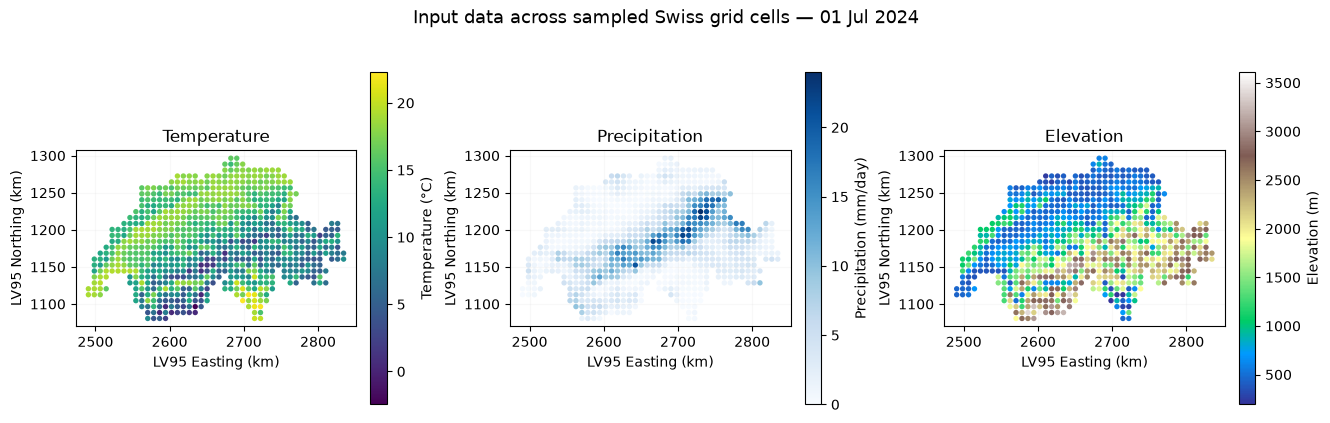

Saved input-data example for: 2024-07-01


In [2]:
df, E_DIM, N_DIM = build_or_load_model_table(
    DIRS,
    start_year=START_YEAR,
    end_year=TEST_YEAR,
    stride=STRIDE,
)

train_raw, valid_raw, test_raw = split_years(
    df,
    train_end=TRAIN_END,
    valid_year=VALID_YEAR,
    test_year=TEST_YEAR,
)

print("Rows:", f"{len(df):,}")
print("Grid cells:", df["cell_id"].nunique())
print("Train targets:", train_raw["target_date"].min(), "→", train_raw["target_date"].max())
print("Validation targets:", valid_raw["target_date"].min(), "→", valid_raw["target_date"].max())
print("Test targets:", test_raw["target_date"].min(), "→", test_raw["target_date"].max())

# One compact input-data figure, following the course emphasis on showing the data
# before interpreting a model result.
input_day = input_data_figure(
    test_raw,
    E_DIM,
    N_DIM,
    DIRS["figures"],
    date="2024-07-01",
)
print("Saved input-data example for:", input_day.date())


## 3. Add historical climatology features

These are learned from the training period only. For training rows themselves, leave-one-out means are used, so a row cannot directly use its own target when its climatology feature is created.

The extra variables are:

- historical mean target temperature for the same cell and month
- typical next-day temperature change for that day of year
- current temperature relative to local monthly climatology
- a seasonally adjusted persistence value

This is a small improvement experiment, not a change to the research question.

In [3]:
train, valid = add_climatology_features(
    train_raw,
    valid_raw,
    target=TARGET,
)

CLIM_FEATURES = [
    "cell_month_clim_C",
    "seasonal_delta_C",
    "temp_vs_clim_C",
    "seasonal_persistence_C",
]

display(train[CLIM_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
cell_month_clim_C,2127220.0,6.603079,7.458818,-14.636173,1.201969,5.945608,12.308309,24.556528
seasonal_delta_C,2127220.0,0.002294,0.733554,-2.040689,-0.469337,0.026593,0.517471,1.831078
temp_vs_clim_C,2127220.0,-0.002294,3.694801,-19.249047,-2.548315,0.062166,2.629613,18.064475
seasonal_persistence_C,2127220.0,6.603079,8.316214,-31.946987,0.675694,6.409837,12.718134,30.371382


## 4. Features and candidate models

In [4]:
WEATHER = [
    "temp_t",
    "temp_lag1",
    "temp_lag2",
    "temp_lag3",
    "precip_t",
    "precip_lag1",
    "temp_mean_3d",
    "sin_doy",
    "cos_doy",
]

EXTENDED = WEATHER + [
    "temp_lag7",
    "temp_mean_7d",
    "temp_std_7d",
    "temp_range_7d",
    "temp_change_1d",
    "precip_sum_3d",
    "ch_temp_mean_t",
    "ch_precip_mean_t",
    "temp_anomaly_ch",
]

XY = WEATHER + ["coord_1", "coord_2"]
XYZ = XY + ["elevation_m"]
EXTENDED_XYZ = EXTENDED + ["coord_1", "coord_2", "elevation_m"]
IMPROVED_XYZ = EXTENDED_XYZ + CLIM_FEATURES

linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

hgb_squared = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.05,
    max_iter=350,
    max_leaf_nodes=31,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)

hgb_absolute = HistGradientBoostingRegressor(
    loss="absolute_error",
    learning_rate=0.05,
    max_iter=350,
    max_leaf_nodes=31,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
)

# One conservative tuning experiment: a bit more tree capacity,
# more regularisation and a slightly smaller learning rate.
hgb_climatology_tuned = HistGradientBoostingRegressor(
    loss="absolute_error",
    learning_rate=0.04,
    max_iter=450,
    max_leaf_nodes=63,
    min_samples_leaf=60,
    l2_regularization=2.0,
    early_stopping=False,
    random_state=42,
)

SPECS = {
    "Linear weather-only": (linear, WEATHER, "direct"),
    "Linear + XY": (linear, XY, "direct"),
    "Linear + XY + elevation": (linear, XYZ, "direct"),
    "HGB + XY": (hgb_squared, XY, "direct"),
    "HGB + XY + elevation": (hgb_squared, XYZ, "direct"),
    "HGB extended": (hgb_squared, EXTENDED_XYZ, "direct"),
    "HGB extended + MAE loss": (hgb_absolute, EXTENDED_XYZ, "direct"),
    "HGB delta-T + MAE loss": (hgb_absolute, EXTENDED_XYZ, "delta"),
    "HGB + climatology": (hgb_absolute, IMPROVED_XYZ, "direct"),
    "HGB seasonal residual": (hgb_absolute, IMPROVED_XYZ, "seasonal_residual"),
    "HGB + climatology tuned": (hgb_climatology_tuned, IMPROVED_XYZ, "direct"),
}

## 5. Model selection on 2023

The new candidates do not get any special treatment: the winner is simply the non-persistence model with the lowest 2023 MAE.

Seasonal-persistence validation MAE: 1.872 °C


,model,MAE_C,RMSE_C,R2,skill_vs_persistence_pct
0,HGB delta-T + MAE loss,1.496,1.976,0.947,16.1
1,HGB extended + MAE loss,1.499,1.985,0.946,15.9
2,HGB extended,1.517,1.985,0.946,14.9
3,HGB seasonal residual,1.532,2.016,0.945,14.0
4,HGB + climatology,1.533,2.015,0.945,14.0
5,HGB + climatology tuned,1.547,2.033,0.944,13.2
6,HGB + XY + elevation,1.590,2.063,0.942,10.8
7,Linear + XY + elevation,1.601,2.066,0.942,10.2
8,HGB + XY,1.619,2.105,0.940,9.2
9,Linear + XY,1.624,2.113,0.939,8.9


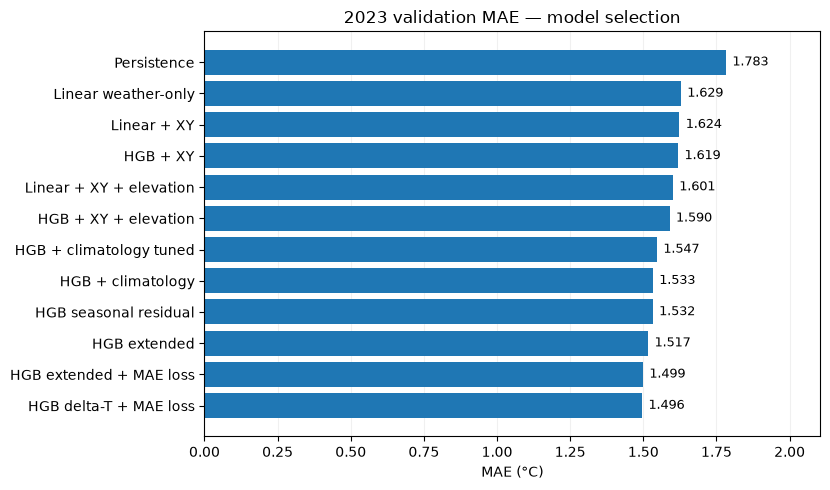

Selected from 2023 validation: HGB delta-T + MAE loss


In [5]:
fitted_validation, validation_scores = fit_forecasters(
    train,
    valid,
    TARGET,
    SPECS,
)

# Add a simple seasonally adjusted persistence baseline for context.
seasonal_mae = (valid[TARGET] - valid["seasonal_persistence_C"]).abs().mean()
print("Seasonal-persistence validation MAE:", f"{seasonal_mae:.3f} °C")

display(
    validation_scores.style.format({
        "MAE_C": "{:.3f}",
        "RMSE_C": "{:.3f}",
        "R2": "{:.3f}",
        "skill_vs_persistence_pct": "{:.1f}",
    })
)

score_bar(
    validation_scores,
    "2023 validation MAE — model selection",
    DIRS["figures"] / "validation_model_comparison_2023.png",
)

validation_scores.to_csv(
    DIRS["results"] / "validation_scores.csv",
    index=False,
)

best_name = (
    validation_scores
    .query("model != 'Persistence'")
    .iloc[0]["model"]
)

print("Selected from 2023 validation:", best_name)

## 6. What information does the selected model use?

,feature,MAE_increase_C
0,cos_doy,0.600
1,ch_temp_mean_t,0.471
2,ch_precip_mean_t,0.380
3,elevation_m,0.271
4,temp_anomaly_ch,0.230
5,temp_lag1,0.078
6,sin_doy,0.074
7,precip_t,0.029
8,precip_lag1,0.012
9,temp_change_1d,0.010


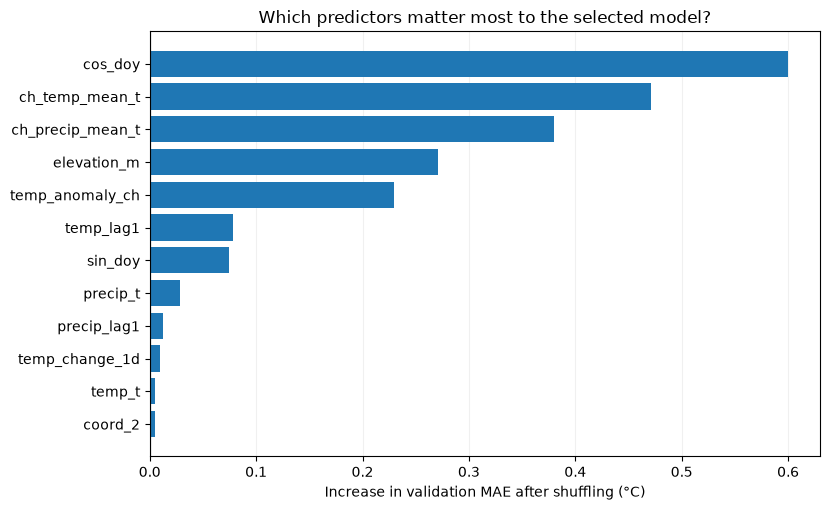

In [6]:
importance = permutation_mae_importance(
    fitted_validation[best_name],
    valid,
    TARGET,
    sample_size=40000,
    random_state=42,
)

display(
    importance.head(15).style.format({
        "MAE_increase_C": "{:.3f}",
    })
)

importance_bar(
    importance,
    top_n=12,
    out_file=DIRS["figures"] / "feature_importance_validation.png",
)

importance.to_csv(
    DIRS["results"] / "feature_importance.csv",
    index=False,
)

## 7. Final 2024 test

The model choice is now frozen. Climatology is rebuilt using all pre-2024 target data, then the selected model is refit on 2015–2023 and evaluated once on 2024.

In [7]:
pre2024_raw = pd.concat([train_raw, valid_raw], ignore_index=True)
pre2024, test = add_climatology_features(
    pre2024_raw,
    test_raw,
    target=TARGET,
)

final_specs = {
    "Linear weather-only": SPECS["Linear weather-only"],
    "HGB + XY + elevation": SPECS["HGB + XY + elevation"],
    f"Selected: {best_name}": SPECS[best_name],
}

fitted_final, test_scores = refit_forecasters(
    pre2024,
    test,
    TARGET,
    final_specs,
)

display(
    test_scores.style.format({
        "MAE_C": "{:.3f}",
        "RMSE_C": "{:.3f}",
        "R2": "{:.3f}",
        "skill_vs_persistence_pct": "{:.1f}",
    })
)


selected_label = f"Selected: {best_name}"
test_results = make_test_results(
    test,
    TARGET,
    fitted_final[selected_label],
    E_DIM,
    N_DIM,
)

test_results.to_parquet(
    DIRS["processed"] / "test_predictions_2024.parquet",
    index=False,
)

joblib.dump(
    fitted_final[selected_label][0],
    DIRS["models"] / "best_temperature_model.joblib",
)

test_scores.to_csv(
    DIRS["results"] / "test_scores_2024.csv",
    index=False,
)

model_info = {
    "selected_model": best_name,
    "validation_MAE_C": float(
        validation_scores.loc[
            validation_scores["model"] == best_name,
            "MAE_C",
        ].iloc[0]
    ),
    "test_MAE_C": float(
        test_scores.loc[
            test_scores["model"] == selected_label,
            "MAE_C",
        ].iloc[0]
    ),
}

(DIRS["models"] / "selected_model.json").write_text(
    json.dumps(model_info, indent=2),
    encoding="utf-8",
)

print("Final selected model:", best_name)
print("Saved 2024 predictions and model.")

,model,MAE_C,RMSE_C,R2,skill_vs_persistence_pct
0,Selected: HGB delta-T + MAE loss,1.569,2.094,0.930,16.2
1,HGB + XY + elevation,1.637,2.161,0.926,12.6
2,Linear weather-only,1.709,2.273,0.918,8.7
3,Persistence,1.872,2.492,0.901,0.0


Final selected model: HGB delta-T + MAE loss
Saved 2024 predictions and model.


## 8. Report figures

The course material treats figures as evidence, not decoration. The saved set therefore gives each visual one main job: show the input data, compare models, show when errors occur, show where errors occur, and inspect residual structure.

Observed and predicted maps use the same temperature scale. MAE uses a sequential colour scale, while signed bias/residuals use a diverging scale centred on zero.


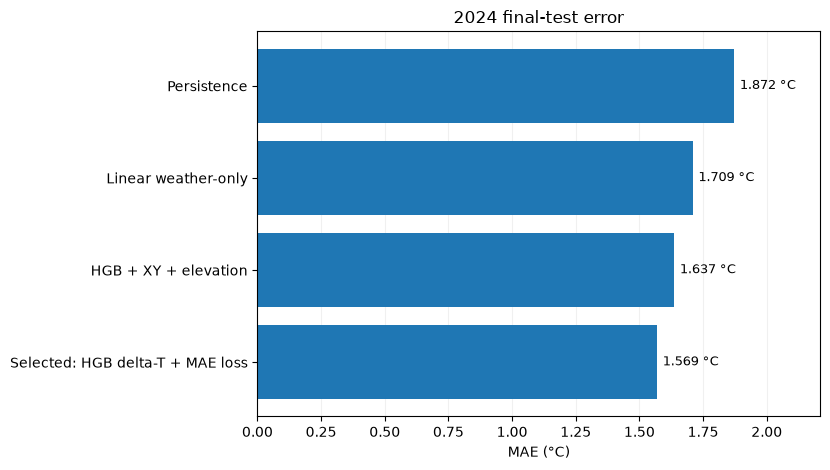

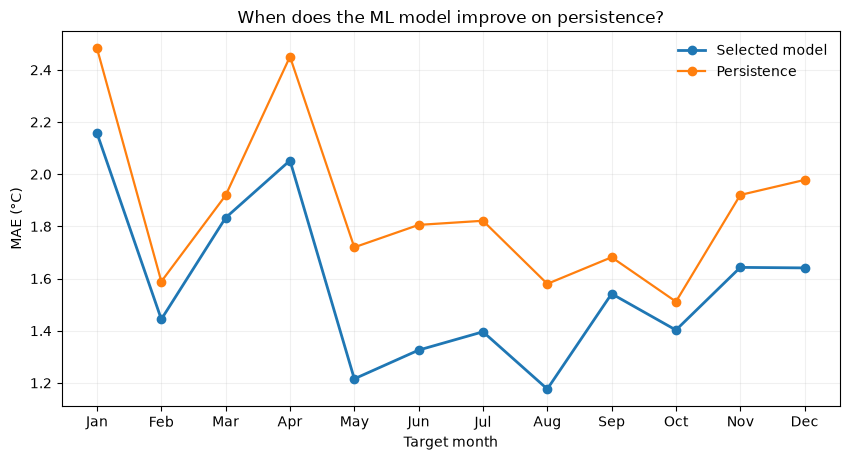

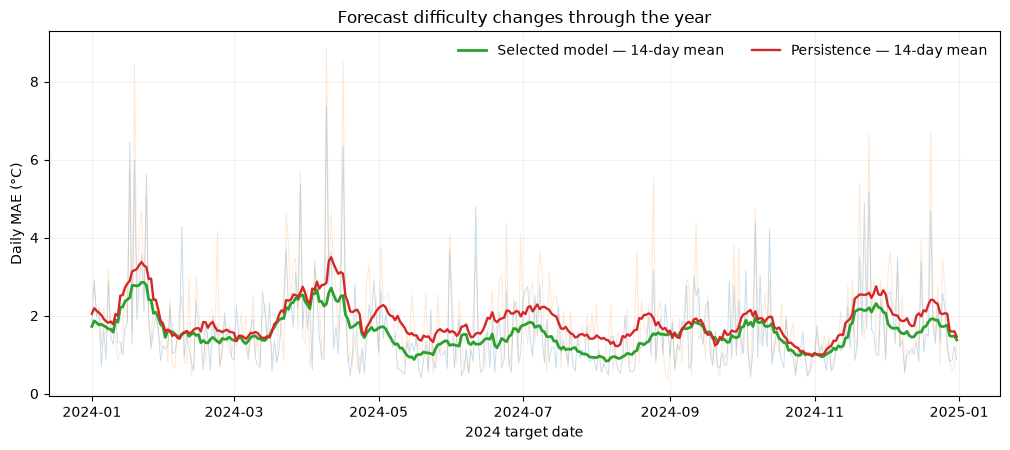

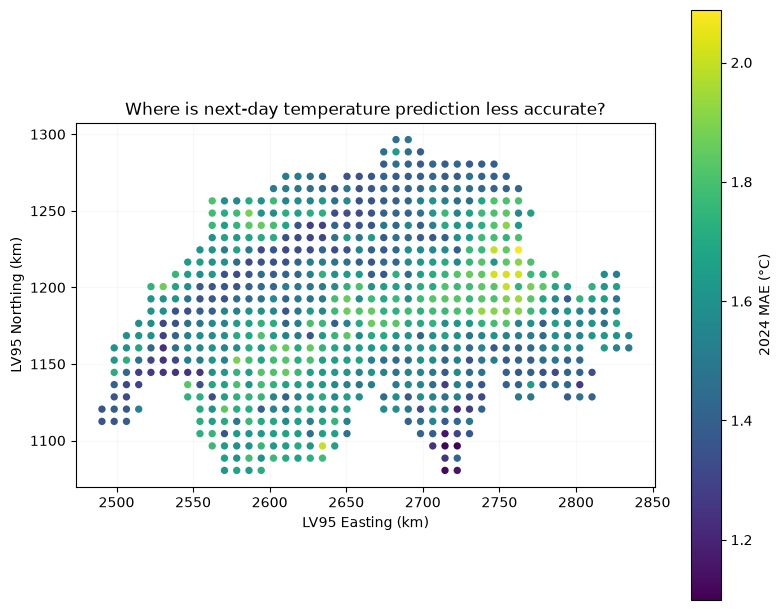

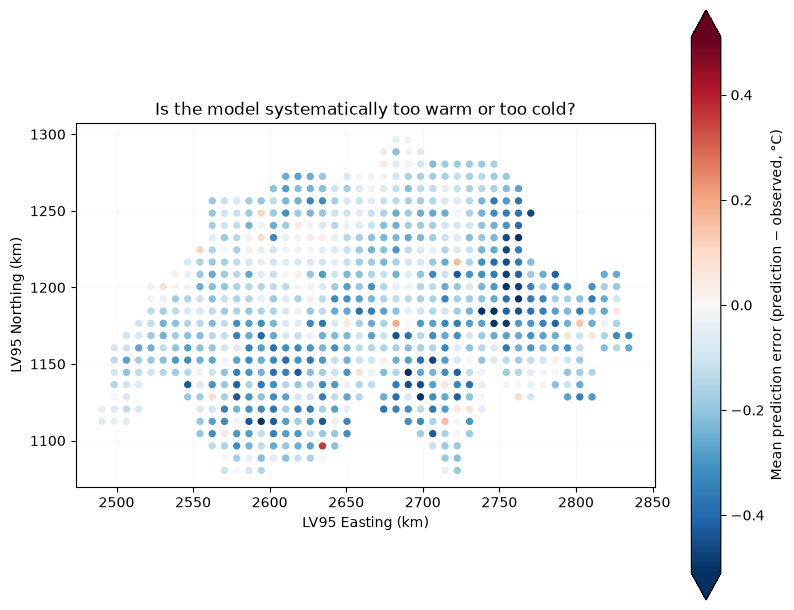

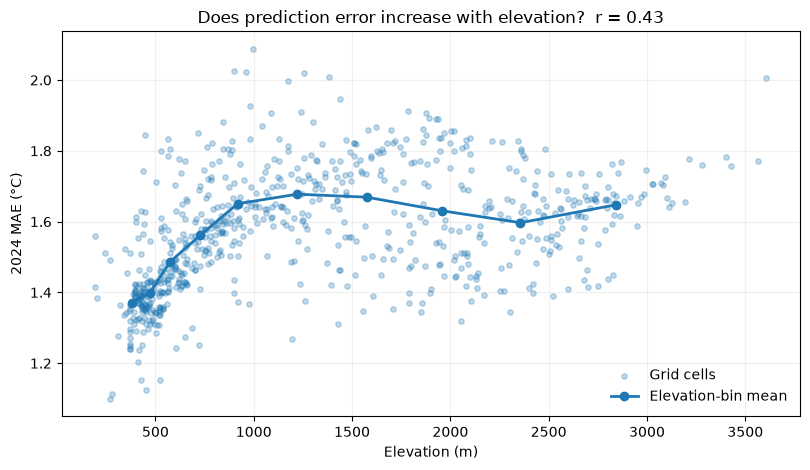

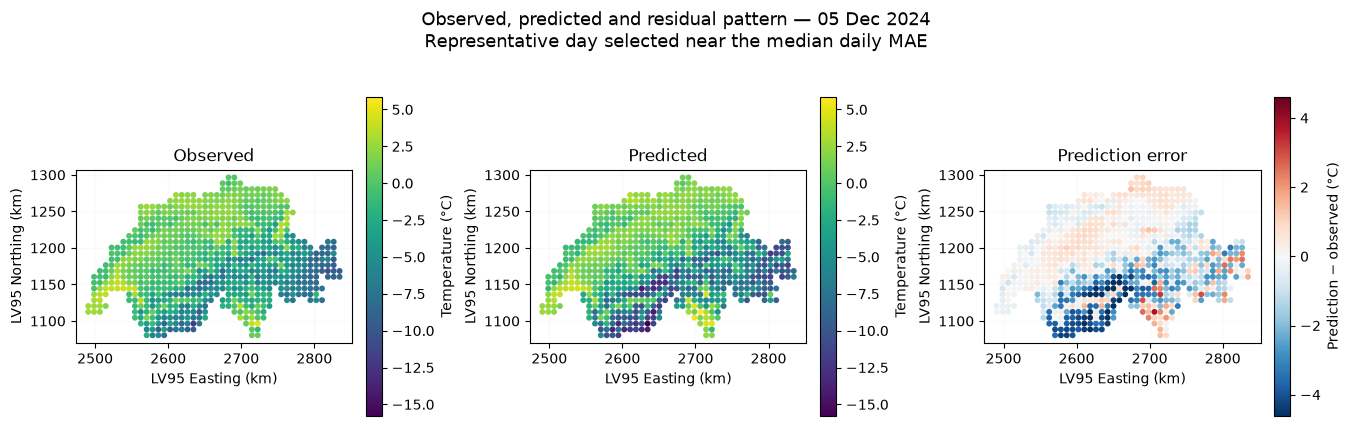

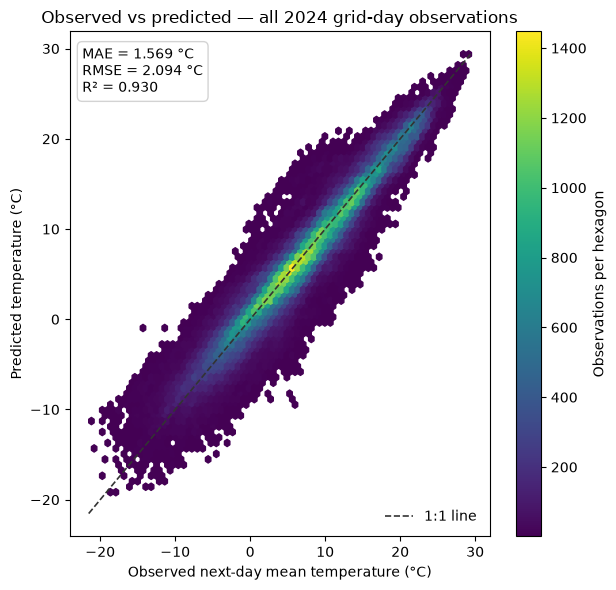

Elevation / cell-MAE correlation: 0.432
Saved report figures to: figures/


In [8]:
monthly_error, daily_error, cell_error, elevation_corr = report_figures(
    test_results,
    test_scores,
    E_DIM,
    N_DIM,
    DIRS["figures"],
)

monthly_error.to_csv(
    DIRS["results"] / "monthly_model_vs_persistence_2024.csv",
    index=False,
)

daily_error.to_csv(
    DIRS["results"] / "daily_model_vs_persistence_2024.csv",
    index=False,
)

cell_error.to_csv(
    DIRS["results"] / "cell_error_2024.csv",
    index=False,
)

print("Elevation / cell-MAE correlation:", f"{elevation_corr:.3f}")
print("Saved report figures to: figures/")

## 9. Interpretation checklist

Keep the final story focused:

1. How much better is the selected model than persistence?
2. Do coordinates and elevation improve over weather-only models?
3. Did climatology or seasonal-residual modelling improve 2023 validation MAE?
4. In which months and locations are errors largest?
5. Is there a relationship between elevation and error?
6. Do the observed / predicted / residual maps reveal a spatial failure pattern?
7. How close is the lightweight model to the external ECMWF benchmark?

Choose the winner only from 2023 validation. The 2024 test year is for final evaluation, not model selection.

### AI use

ChatGPT was used as a support tool for debugging, code structure, visualisation ideas and discussion of modelling choices. The workflow and outputs should be run and checked by the student, and AI use should be disclosed transparently in the final report.
